# Lacet : rajouter un angle dans l'environnement

Tâche avancée du sujet : *« Make the drone rotate on itself at the end of step 2 »*. On veut ajouter l'angle de
lacet $\psi$ (rotation autour de l'axe vertical) à l'environnement de Track B (`rl_interface/Env_drone.py`), pour que
le drone fasse un tour sur lui-même pendant le palier à 0.5 m.

1. Le modèle actuel ne peut pas tourner : une seule commande $u$, envoyée aux 4 moteurs. On ajoute une commande
   différentielle $\delta$.
2. Simulations sur `UAV_model.slx` pour trouver **la paire de moteurs**, **leur disposition**, **le sens de
   rotation** et **le couplage avec l'altitude**.
3. Identification du modèle de lacet sur 100 vols, et modèle Python `rl_interface/modele_lacet.py`.
4. Le nouvel environnement `rl_interface/Env_drone_lacet.py` : mission, observation, récompense, et vols d'essai.

Les simulations sont faites sous MATLAB par `generer_donnees_lacet.m` (~4 min). Il écrit `tests_lacet.mat` (essais
sans bruit des parties 3 à 6) et `donnees_lacet.mat` (100 vols bruités de la partie 7). Ce notebook les lit et les
analyse.

In [1]:
import inspect
import subprocess
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Circle, FancyBboxPatch
from scipy.io import loadmat

RELANCER_MATLAB = False     # True : refait toutes les simulations (MATLAB dans le PATH, ~4 min)
if RELANCER_MATLAB or not Path("tests_lacet.mat").exists():
    subprocess.run(["matlab", "-batch", "generer_donnees_lacet"], check=True)

T = loadmat("tests_lacet.mat", squeeze_me=True)
NOMS = list(T["NOMS"])                              # les 18 sorties de UAV_model, dans l'ordre
def col(Y, nom):
    return Y[..., NOMS.index(nom)]

Ts, u_h, T_DEBUT, DELTA_TEST = float(T["Ts"]), float(T["u_h"]), float(T["T_DEBUT"]), float(T["DELTA_TEST"])
t = T["t_test"]
S = T["S"]                                          # répartition retenue (partie 3)
G = 9.81
print(f"Ts = {Ts} s ; vol stationnaire : u_h = {u_h:.4f}")

Ts = 0.05 s ; vol stationnaire : u_h = 0.3895


## 1. Pourquoi le drone ne peut pas tourner

Dans `EINT_RL_closed_loop.slx`, la commande $u$ de la policy est branchée sur les 4 entrées `u1` à `u4` de
`UAV_model`. Dans `UAV_model.slx`, chaque moteur passe par un filtre $1/(0.2s+1)$, puis $F_i = 10\tanh(m_i)$, puis la
dynamique `quadcopter_model.p`, qui est protégée. Quatre forces identiques ne créent aucun couple de lacet. Les
données fournies n'ont, elles aussi, qu'une entrée $u$ et qu'une sortie $a_z$ : le RNN $u \to a_z$ ne sait rien du
lacet.

On ajoute donc une **commande différentielle** $\delta$ et un mélangeur : $u_i = u + s_i\,\delta$ avec $s_i = \pm 1$,
deux moteurs à $+\delta$ et deux à $-\delta$. Deux moteurs tournent plus vite que les deux autres, ce qui crée un
couple de lacet, et la poussée totale ne change presque pas (partie 6). Il reste à trouver quels moteurs mettre
ensemble.

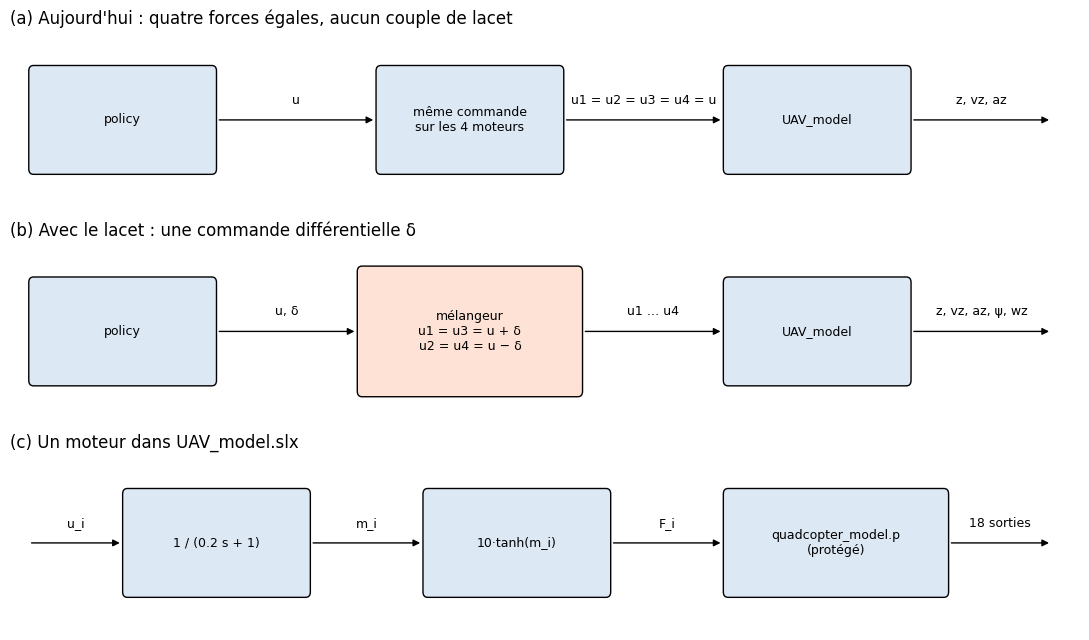

In [2]:
def bloc(ax, x, y, texte, w=1.9, h=0.9, couleur="#dde8f5"):
    ax.add_patch(FancyBboxPatch((x - w / 2, y - h / 2), w, h, boxstyle="round,pad=0.05", fc=couleur, ec="black"))
    ax.text(x, y, texte, ha="center", va="center", fontsize=9)

def fleche(ax, x0, x1, texte="", y=0.0):
    ax.annotate("", xy=(x1, y), xytext=(x0, y), arrowprops=dict(arrowstyle="-|>", color="black"))
    ax.text((x0 + x1) / 2, y + 0.12, texte, ha="center", va="bottom", fontsize=9)

fig, axs = plt.subplots(3, 1, figsize=(11, 6.5))
ax = axs[0]
bloc(ax, 1, 0, "policy")
fleche(ax, 2.0, 3.7, "u")
bloc(ax, 4.7, 0, "même commande\nsur les 4 moteurs")
fleche(ax, 5.7, 7.4, "u1 = u2 = u3 = u4 = u")
bloc(ax, 8.4, 0, "UAV_model")
fleche(ax, 9.4, 10.9, "z, vz, az")
ax.set_title("(a) Aujourd'hui : quatre forces égales, aucun couple de lacet", loc="left")

ax = axs[1]
bloc(ax, 1, 0, "policy")
fleche(ax, 2.0, 3.5, "u, δ")
bloc(ax, 4.7, 0, "mélangeur\nu1 = u3 = u + δ\nu2 = u4 = u − δ", w=2.3, h=1.1, couleur="#fde2d5")
fleche(ax, 5.9, 7.4, "u1 … u4")
bloc(ax, 8.4, 0, "UAV_model")
fleche(ax, 9.4, 10.9, "z, vz, az, ψ, wz")
ax.set_title("(b) Avec le lacet : une commande différentielle δ", loc="left")

ax = axs[2]
fleche(ax, 0.0, 1.0, "u_i")
bloc(ax, 2.0, 0, "1 / (0.2 s + 1)")
fleche(ax, 3.0, 4.2, "m_i")
bloc(ax, 5.2, 0, "10·tanh(m_i)")
fleche(ax, 6.2, 7.4, "F_i")
bloc(ax, 8.6, 0, "quadcopter_model.p\n(protégé)", w=2.3)
fleche(ax, 9.8, 10.9, "18 sorties")
ax.set_title("(c) Un moteur dans UAV_model.slx", loc="left")

for ax in axs:
    ax.set_xlim(-0.2, 11.2); ax.set_ylim(-0.8, 0.8); ax.axis("off")
plt.tight_layout()
plt.show()

## 2. Vol stationnaire

Tous les essais partent du vol stationnaire : $u_h$ tel que $a_z = 0$, trouvé par la méthode de la sécante, sans
bruit. On obtient $u_h = 0.3895$ (valeur affichée plus haut). Au départ, les moteurs sont arrêtés (le filtre de
0.2 s), donc le drone chute un peu avant d'être en vol stationnaire. C'est pourquoi chaque essai est comparé à un
vol de référence avec les mêmes $u$ et $\delta = 0$.

## 3. Quelle paire de moteurs ?

Il y a trois façons de mettre deux moteurs à $+\delta$ et deux à $-\delta$. Pour chacune, on applique
$\delta = 0.05$ à partir de $t = 1$ s, en vol stationnaire et sans bruit. La bonne paire fait tourner le drone
($w_z$) sans le faire basculer ($w_x = w_y = 0$).

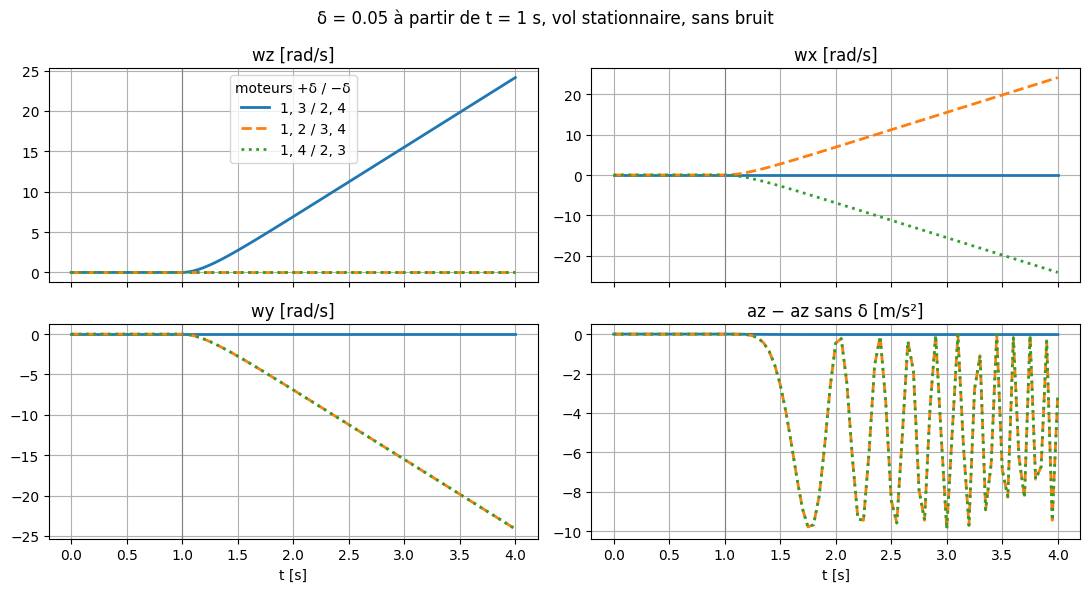

,wz après 3 s [rad/s],max |wx| [rad/s],max |wy| [rad/s],"max |φ|, |θ| [rad]",Δaz moyen [m/s²]
moteurs +δ / −δ,,,,,
"1, 3 / 2, 4",24.139,0.000,0.000,0.00,-0.019
"1, 2 / 3, 4",0.000,24.139,24.139,33.97,-4.344
"1, 4 / 2, 3",0.000,24.139,24.139,33.97,-4.344


In [3]:
LABELS = ["1, 3 / 2, 4", "1, 2 / 3, 4", "1, 4 / 2, 3"]
Y_ref, Y_rep = T["Y_ref"], T["Y_rep"]
apres = t >= T_DEBUT

fig, axs = plt.subplots(2, 2, figsize=(11, 6), sharex=True)
titres = {"wz": "wz [rad/s]", "wx": "wx [rad/s]", "wy": "wy [rad/s]", "az": "az − az sans δ [m/s²]"}
for (nom, titre), ax in zip(titres.items(), axs.ravel()):
    for r in range(3):
        y = col(Y_rep[r], nom) - (col(Y_ref, nom) if nom == "az" else 0)
        ax.plot(t, y, ls=["-", "--", ":"][r], lw=2, label=LABELS[r])
    ax.axvline(T_DEBUT, color="gray", lw=0.8)
    ax.set_title(titre); ax.grid(True)
axs[0, 0].legend(title="moteurs +δ / −δ")
for ax in axs[1]:
    ax.set_xlabel("t [s]")
fig.suptitle(f"δ = {DELTA_TEST} à partir de t = {T_DEBUT:g} s, vol stationnaire, sans bruit")
plt.tight_layout()
plt.show()

pd.DataFrame({
    "wz après 3 s [rad/s]": [col(Y, "wz")[-1] for Y in Y_rep],
    "max |wx| [rad/s]": [np.abs(col(Y, "wx")).max() for Y in Y_rep],
    "max |wy| [rad/s]": [np.abs(col(Y, "wy")).max() for Y in Y_rep],
    "max |φ|, |θ| [rad]": [max(np.abs(col(Y, "phi")).max(), np.abs(col(Y, "theta")).max()) for Y in Y_rep],
    "Δaz moyen [m/s²]": [np.mean(col(Y, "az")[apres] - col(Y_ref, "az")[apres]) for Y in Y_rep],
}, index=pd.Index(LABELS, name="moteurs +δ / −δ")).round(3)

**On retient : moteurs 1 et 3 à $+\delta$, moteurs 2 et 4 à $-\delta$**, soit $s = [1, -1, 1, -1]$. Avec cette
paire, $w_z$ atteint 24 rad/s après 3 s, et $w_x$, $w_y$, $\varphi$, $\theta$ restent exactement nuls. Les deux autres
répartitions font basculer le drone ($\varphi$, $\theta \approx 34$ rad : il fait des tonneaux). Sa poussée n'est
alors plus verticale, et $a_z$ oscille entre 0 et −10 m/s² (−4.3 m/s² en moyenne).

## 4. Où sont les moteurs ? (schéma déduit des essais)

Le modèle est protégé, mais les essais de la partie 3 donnent la disposition des moteurs. On suppose un repère
direct avec $z$ vers le haut (au repos, $a_z = -9.81$). Une force $F_i$ vers le haut, appliquée au point
$(x_i, y_i)$, crée un couple de roulis $\tau_x = y_i F_i$ et un couple de tangage $\tau_y = -x_i F_i$.

- La répartition 1, 3 / 2, 4 ne crée ni roulis ni tangage : les moteurs 1 et 3 sont opposés, comme les moteurs 2 et 4.
- 1, 2 / 3, 4 donne $w_x > 0$ et $w_y < 0$ ; 1, 4 / 2, 3 donne $w_x < 0$ et $w_y < 0$, avec la même amplitude.

Une seule disposition est compatible : la **configuration « + »**, avec le moteur 1 sur $+x$, le 2 sur $+y$, le 3
sur $-x$ et le 4 sur $-y$. Le tableau vérifie les signes prévus pour cette disposition.

In [4]:
POS = {1: (1, 0), 2: (0, 1), 3: (-1, 0), 4: (0, -1)}     # configuration « + » déduite
signe = lambda v: int(np.sign(np.round(v, 6)))
lignes = []
for r, lab in enumerate(LABELS):
    s = T["REPARTITIONS"][r]
    tau_x = sum(s[i - 1] * POS[i][1] for i in POS)
    tau_y = -sum(s[i - 1] * POS[i][0] for i in POS)
    lignes.append([lab, signe(tau_x), signe(col(Y_rep[r], "wx")[-1]), signe(tau_y), signe(col(Y_rep[r], "wy")[-1])])
pd.DataFrame(lignes, columns=["moteurs +δ / −δ", "τx prévu", "wx simulé", "τy prévu", "wy simulé"]).set_index("moteurs +δ / −δ")

,τx prévu,wx simulé,τy prévu,wy simulé
moteurs +δ / −δ,,,,
"1, 3 / 2, 4",0,0,0,0
"1, 2 / 3, 4",1,1,-1,-1
"1, 4 / 2, 3",-1,-1,-1,-1


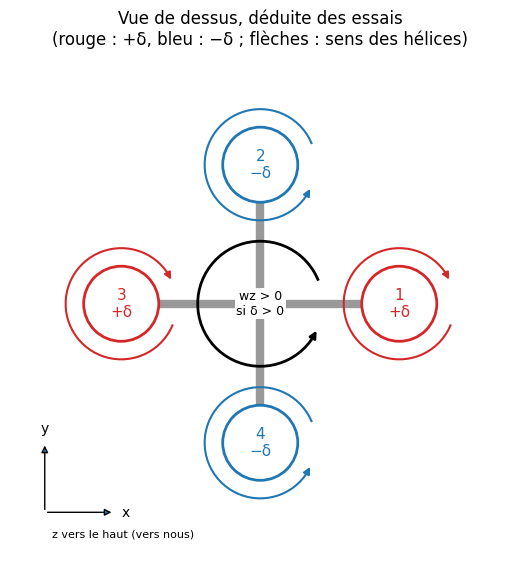

In [5]:
def fleche_ronde(ax, centre, rayon, sens, couleur, lw=1.5):
    # arc presque complet, sens = +1 : anti-horaire, -1 : horaire (vu de dessus)
    a = np.linspace(0.4, 2 * np.pi - 0.4, 60)[::sens]
    x, y = centre[0] + rayon * np.cos(a), centre[1] + rayon * np.sin(a)
    ax.plot(x[:-2], y[:-2], color=couleur, lw=lw)
    ax.annotate("", xy=(x[-1], y[-1]), xytext=(x[-3], y[-3]),
                arrowprops=dict(arrowstyle="-|>", color=couleur, lw=lw))

fig, ax = plt.subplots(figsize=(6.5, 6.5))
for i, (x, y) in POS.items():
    ax.plot([0, x], [0, y], color="0.6", lw=6, zorder=1, solid_capstyle="round")
for i, (x, y) in POS.items():
    plus = S[i - 1] > 0
    c = "tab:red" if plus else "tab:blue"
    ax.add_patch(Circle((x, y), 0.27, fc="white", ec=c, lw=2, zorder=2))
    ax.text(x, y, f"{i}\n{'+δ' if plus else '−δ'}", ha="center", va="center", color=c, fontsize=11, zorder=3)
    fleche_ronde(ax, (x, y), 0.4, -1 if plus else 1, c)       # hélices : 1, 3 horaires ; 2, 4 anti-horaires
fleche_ronde(ax, (0, 0), 0.45, 1, "black", lw=2)              # corps : wz > 0 quand δ > 0
ax.text(0, 0, "wz > 0\nsi δ > 0", ha="center", va="center", fontsize=9, zorder=3,
        bbox=dict(fc="white", ec="none", pad=1))
ax.annotate("", xy=(-1.05, -1.5), xytext=(-1.55, -1.5), arrowprops=dict(arrowstyle="-|>"))
ax.annotate("", xy=(-1.55, -1.0), xytext=(-1.55, -1.5), arrowprops=dict(arrowstyle="-|>"))
ax.text(-1.0, -1.5, "x", va="center"); ax.text(-1.55, -0.93, "y", ha="center")
ax.text(-1.5, -1.68, "z vers le haut (vers nous)", fontsize=8)
ax.set_xlim(-1.8, 1.8); ax.set_ylim(-1.8, 1.8); ax.set_aspect("equal"); ax.axis("off")
ax.set_title("Vue de dessus, déduite des essais\n(rouge : +δ, bleu : −δ ; flèches : sens des hélices)")
plt.show()

Le sens des hélices est déduit en supposant un modèle physique : le couple de réaction sur le corps est opposé à la
rotation des hélices. Comme accélérer les moteurs 1 et 3 fait tourner le corps dans le sens anti-horaire, les
hélices 1 et 3 tournent dans le sens horaire, et les hélices 2 et 4 dans le sens anti-horaire.

## 5. Sens de rotation

Avec la paire retenue, on fait varier $\delta$, y compris en négatif, toujours en vol stationnaire.

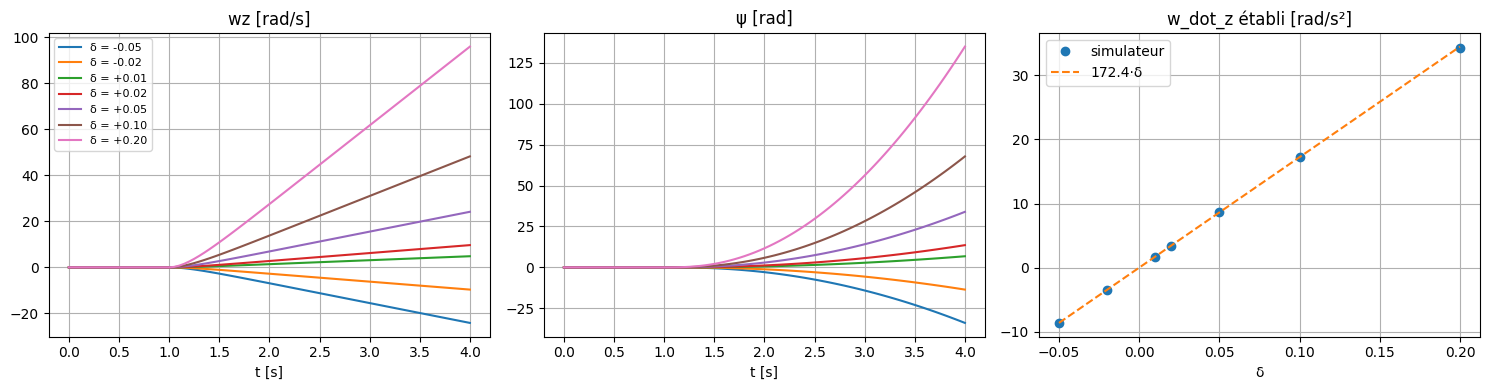

w_dot_z ≈ 172.4·δ en vol stationnaire ; à δ = 0.2 : 34.23 au lieu de 34.48 (tanh)


In [6]:
DELTAS, Y_d = T["DELTAS"], T["Y_delta"]
fig, axs = plt.subplots(1, 3, figsize=(15, 4))
for d, Y in zip(DELTAS, Y_d):
    axs[0].plot(t, col(Y, "wz"), label=f"δ = {d:+.2f}")
    axs[1].plot(t, col(Y, "psi"))
wdz_palier = np.array([col(Y, "w_dot_z")[-1] for Y in Y_d])     # filtre moteur établi
petits = np.abs(DELTAS) <= 0.05
pente = np.polyfit(DELTAS[petits], wdz_palier[petits], 1)[0]
dd = np.linspace(DELTAS.min(), DELTAS.max(), 50)
axs[2].plot(DELTAS, wdz_palier, "o", label="simulateur")
axs[2].plot(dd, pente * dd, "--", label=f"{pente:.1f}·δ")
axs[0].set(title="wz [rad/s]", xlabel="t [s]"); axs[0].legend(fontsize=8)
axs[1].set(title="ψ [rad]", xlabel="t [s]")
axs[2].set(title="w_dot_z établi [rad/s²]", xlabel="δ"); axs[2].legend()
for ax in axs:
    ax.grid(True)
plt.tight_layout()
plt.show()
print(f"w_dot_z ≈ {pente:.1f}·δ en vol stationnaire ; à δ = 0.2 : {wdz_palier[-1]:.2f} au lieu de {pente * 0.2:.2f} (tanh)")

- **$\delta > 0$ donne $w_z > 0$** et $\psi$ croissant : le drone tourne dans le sens direct, anti-horaire vu de
  dessus. Avec $\delta < 0$, c'est l'inverse, de façon symétrique.
- $\dot w_z$ est proportionnel à $\delta$ : environ $172\,\delta$ en vol stationnaire. À $\delta = 0.2$, il est un
  peu plus faible (−0.8 %) à cause de la courbure de tanh.
- **Il n'y a aucun amortissement** : $w_z$ croît linéairement tant que $\delta \neq 0$, et $\psi$ croît comme
  $t^2$. Pour s'arrêter sur un angle, la commande doit freiner avec un $\delta$ de signe opposé.

## 6. Couplage avec l'altitude

Avec deux moteurs à $u+\delta$ et deux à $u-\delta$, la poussée moyenne baisse un peu, car tanh est courbée. Si
$a_z + g = K \cdot \text{moyenne}(\tanh m_i)$, avec $K = g / \tanh u_h$ (vol stationnaire), un développement à
l'ordre 2 donne :

$$\Delta a_z \approx \tfrac12 K \tanh''(u)\,\delta^2 = -K \tanh(u)\,(1-\tanh^2 u)\,\delta^2
\quad\Rightarrow\quad \Delta a_z(u_h) \approx -g\,(1-\tanh^2 u_h)\,\delta^2 \approx -8.5\,\delta^2$$

On le vérifie de deux façons : en faisant varier $\delta$ en vol stationnaire, puis en faisant varier $u$ à
$\delta = 0.05$. Ce second balayage montre aussi que l'efficacité de $\delta$ sur le lacet dépend de $u$.

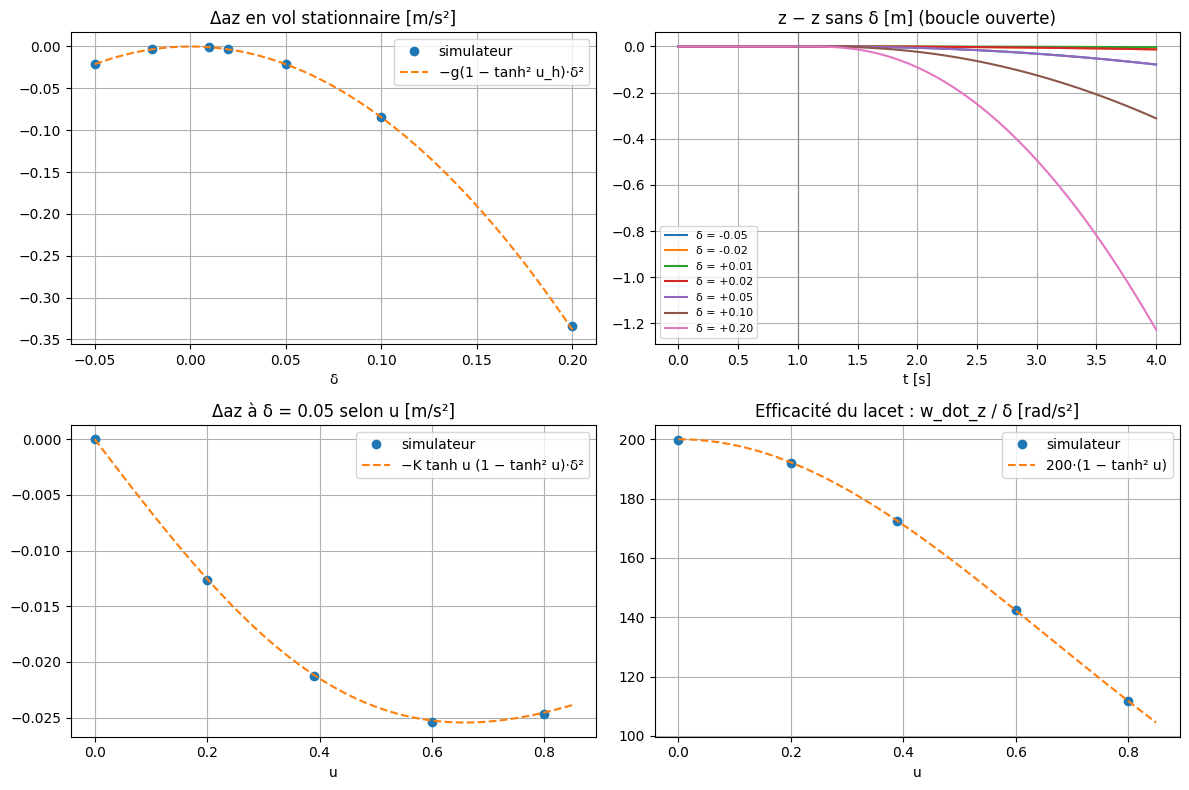

K = g / tanh(u_h) = 26.45 m/s²
à δ = 0.05 : Δaz = -0.0213 m/s², Δz après 3 s = -7.8 cm
roulis, tangage avec la paire retenue : max |wx|, |wy| = 0.0e+00, 0.0e+00 rad/s


In [7]:
U_NIV, Y_u, Y_u_ref = T["U_NIVEAUX"], T["Y_u"], T["Y_u_ref"]
K = G / np.tanh(u_h)
etabli = t >= 2.0
daz_d = np.array([np.mean(col(Y, "az")[etabli] - col(Y_ref, "az")[etabli]) for Y in Y_d])
daz_u = np.array([np.mean(col(Y, "az")[etabli] - col(Yr, "az")[etabli]) for Y, Yr in zip(Y_u, Y_u_ref)])
eff_u = np.array([col(Y, "w_dot_z")[-1] for Y in Y_u]) / DELTA_TEST
uu = np.linspace(0, 0.85, 50)

fig, axs = plt.subplots(2, 2, figsize=(12, 8))
ax = axs[0, 0]
ax.plot(DELTAS, daz_d, "o", label="simulateur")
ax.plot(dd, -K * np.tanh(u_h) * (1 - np.tanh(u_h) ** 2) * dd ** 2, "--", label="−g(1 − tanh² u_h)·δ²")
ax.set(title="Δaz en vol stationnaire [m/s²]", xlabel="δ"); ax.legend()
ax = axs[0, 1]
for d, Y in zip(DELTAS, Y_d):
    ax.plot(t, col(Y, "z") - col(Y_ref, "z"), label=f"δ = {d:+.2f}")
ax.axvline(T_DEBUT, color="gray", lw=0.8)
ax.set(title="z − z sans δ [m] (boucle ouverte)", xlabel="t [s]"); ax.legend(fontsize=8)
ax = axs[1, 0]
ax.plot(U_NIV, daz_u, "o", label="simulateur")
ax.plot(uu, -K * np.tanh(uu) * (1 - np.tanh(uu) ** 2) * DELTA_TEST ** 2, "--", label="−K tanh u (1 − tanh² u)·δ²")
ax.set(title=f"Δaz à δ = {DELTA_TEST} selon u [m/s²]", xlabel="u"); ax.legend()
ax = axs[1, 1]
ax.plot(U_NIV, eff_u, "o", label="simulateur")
ax.plot(uu, 200 * (1 - np.tanh(uu) ** 2), "--", label="200·(1 − tanh² u)")
ax.set(title="Efficacité du lacet : w_dot_z / δ [rad/s²]", xlabel="u"); ax.legend()
for ax in axs.ravel():
    ax.grid(True)
plt.tight_layout()
plt.show()

print(f"K = g / tanh(u_h) = {K:.2f} m/s²")
print(f"à δ = 0.05 : Δaz = {daz_d[DELTAS == 0.05][0]:.4f} m/s², "
      f"Δz après 3 s = {(col(Y_d[DELTAS == 0.05][0], 'z') - col(Y_ref, 'z'))[-1] * 100:.1f} cm")
print(f"roulis, tangage avec la paire retenue : max |wx|, |wy| = {np.abs(col(Y_d, 'wx')).max():.1e}, "
      f"{np.abs(col(Y_d, 'wy')).max():.1e} rad/s")

- **Roulis et tangage : aucun couplage.** $w_x$ et $w_y$ restent exactement nuls, quel que soit $\delta$.
- **Altitude : couplage du second ordre**, bien prévu par $-K\tanh u\,(1-\tanh^2 u)\,\delta^2$. À $\delta = 0.05$
  (assez pour la mission, voir partie 7), on a $\Delta a_z \approx -0.02$ m/s², soit 8 cm perdus en 3 s en boucle
  ouverte. La commande d'altitude rattrape facilement cet écart. **Le RNN $u \to a_z$ reste donc valable** ; on peut
  négliger le couplage, ou ajouter ce terme à $a_z$ dans l'environnement.
- **L'efficacité de $\delta$ dépend de $u$** : $200\,(1-\tanh^2 u)$, soit 200 à $u = 0$, 172 en vol stationnaire et
  84 à $u = 1$. En montée, quand $u$ est saturé, le lacet est deux fois moins efficace, et $u \pm \delta$ est
  écrêté à 1. Mieux vaut donc tourner pendant le palier, une fois le drone stabilisé.

## 7. Modèle du lacet identifié sur les données

Les parties 5 et 6 suggèrent la structure du modèle : $\dot w_z = k \sum_i s_i \tanh(m_i)$, avec $m_i$ la commande
du moteur $i$ filtrée. On l'identifie sur `donnees_lacet.mat`, qui contient 100 vols de 20 s générés avec
g_noise = 0.01 :
- $u$ : paliers aléatoires dans $[-1, 1]$, tenus de 0.2 à 1 s (même plage que les données fournies) ;
- $\delta$ : paliers dans $[-0.05, 0.05]$, dont un sur trois est nul ;
- moteurs $u \pm \delta$ bornés à $[-1, 1]$.

On ajuste sur les 80 premiers vols et on valide sur les 20 derniers. Le filtre moteur est discrétisé exactement
(commande bloquée sur $T_s$) : $m_i[k+1] = a\,m_i[k] + (1-a)\,u_i[k]$, avec $a = e^{-T_s/0.2}$.

In [8]:
D = loadmat("donnees_lacet.mat", squeeze_me=True)
M, wdz, wz, psi, delta, u = D["moteurs"], D["w_dot_z"], D["wz"], D["psi"], D["delta"], D["u"]
A = np.exp(-Ts / 0.2)
m = np.zeros_like(M)
for k in range(1, M.shape[1]):
    m[:, k] = A * m[:, k - 1] + (1 - A) * M[:, k - 1]
couple = (np.tanh(m) * S).sum(axis=2)                # Σ s_i tanh(m_i)

app, val = slice(0, 80), slice(80, 100)
def regression(nom, X):                              # w_dot_z[k] = X[k] @ coef
    X_app = np.stack([x[app, 1:].ravel() for x in X], axis=1)
    X_val = np.stack([x[val, 1:].ravel() for x in X], axis=1)
    coef = np.linalg.lstsq(X_app, wdz[app, 1:].ravel(), rcond=None)[0]
    res = wdz[val, 1:].ravel() - X_val @ coef
    return [nom, np.array2string(coef, precision=4), 1 - res.var() / wdz[val, 1:].var(), res.std()]

delta_avant = np.c_[np.zeros(len(delta)), delta[:, :-1]]   # δ du pas précédent
pd.DataFrame([regression("δ (linéaire, sans filtre)", [delta_avant]),
              regression("Σ s_i tanh(m_i)", [couple]),
              regression("Σ s_i tanh(m_i) et wz (amortissement ?)", [couple, wz])],
             columns=["w_dot_z expliqué par", "coefficients", "R² validation", "résidu [rad/s²]"]).set_index("w_dot_z expliqué par")

,coefficients,R² validation,résidu [rad/s²]
w_dot_z expliqué par,,,
"δ (linéaire, sans filtre)",[117.1744],0.742667,1.716289
Σ s_i tanh(m_i),[50.],1.000000,0.000451
Σ s_i tanh(m_i) et wz (amortissement ?),[5.0000e+01 1.1385e-07],1.000000,0.000451


Le modèle $\dot w_z = 50 \sum_i s_i \tanh(m_i)$ est **exact** : son résidu, $4\cdot10^{-4}$, est le bruit de
mesure. Le coefficient sur $w_z$ est nul, ce qui confirme qu'il n'y a pas d'amortissement. On retrouve aussi la
pente de la partie 5 : près de $u$, $\sum_i s_i \tanh(u + s_i\delta) \approx 4\,\delta\,(1-\tanh^2 u)$, d'où
$\dot w_z \approx 200\,(1-\tanh^2 u)\,\delta$. Un modèle linéaire en $\delta$ ne suffit pas ($R^2 = 0.74$) : il
ignore le filtre moteur et la dépendance en $u$.

Ce modèle tient en quelques lignes, il n'y a pas besoin d'un réseau de neurones. Il est codé dans
`rl_interface/modele_lacet.py`, sur le modèle de `modele_rnn.py`, et le nouvel environnement l'utilise à côté du RNN.
Le filtre moteur bouge pendant $T_s$, donc le pas est intégré en 10 sous-pas. On valide la classe en rejouant les
commandes des 20 vols de validation, en boucle ouverte sur 20 s.

In [9]:
sys.path.insert(0, str(Path("..", "rl_interface").resolve()))
from modele_lacet import ModeleLacet
print(inspect.getsource(ModeleLacet))

class ModeleLacet:

    def __init__(self):
        self.reset()

    # moteurs au repos, drone immobile
    def reset(self):
        self.m = np.zeros(4)           # commandes moteur filtrées
        self.wz = 0.0                  # vitesse de lacet [rad/s]
        self.psi = 0.0                 # angle de lacet [rad], pas ramené dans [-π, π] (comme le simulateur)

    # avancer d'un pas : u et δ tenus pendant Ts, renvoie w_dot_z à la fin du pas
    def step(self, u, delta):
        moteurs = np.clip(u + delta * S, -1.0, 1.0)     # le mélangeur
        h = TS / N_SOUS_PAS
        a = np.exp(-h / TAU)                            # filtre moteur discrétisé exactement
        for _ in range(N_SOUS_PAS):
            wdz = K_LACET * np.sum(S * np.tanh(self.m))
            self.m = a * self.m + (1 - a) * moteurs
            wdz_fin = K_LACET * np.sum(S * np.tanh(self.m))
            wz_fin = self.wz + 0.5 * (wdz + wdz_fin) * h          # trapèzes
            self.psi += 0.5 * (self.wz + wz_f

20 vols de validation, 20 s en boucle ouverte : erreur max sur wz = 0.002 rad/s, sur ψ = 0.006 rad


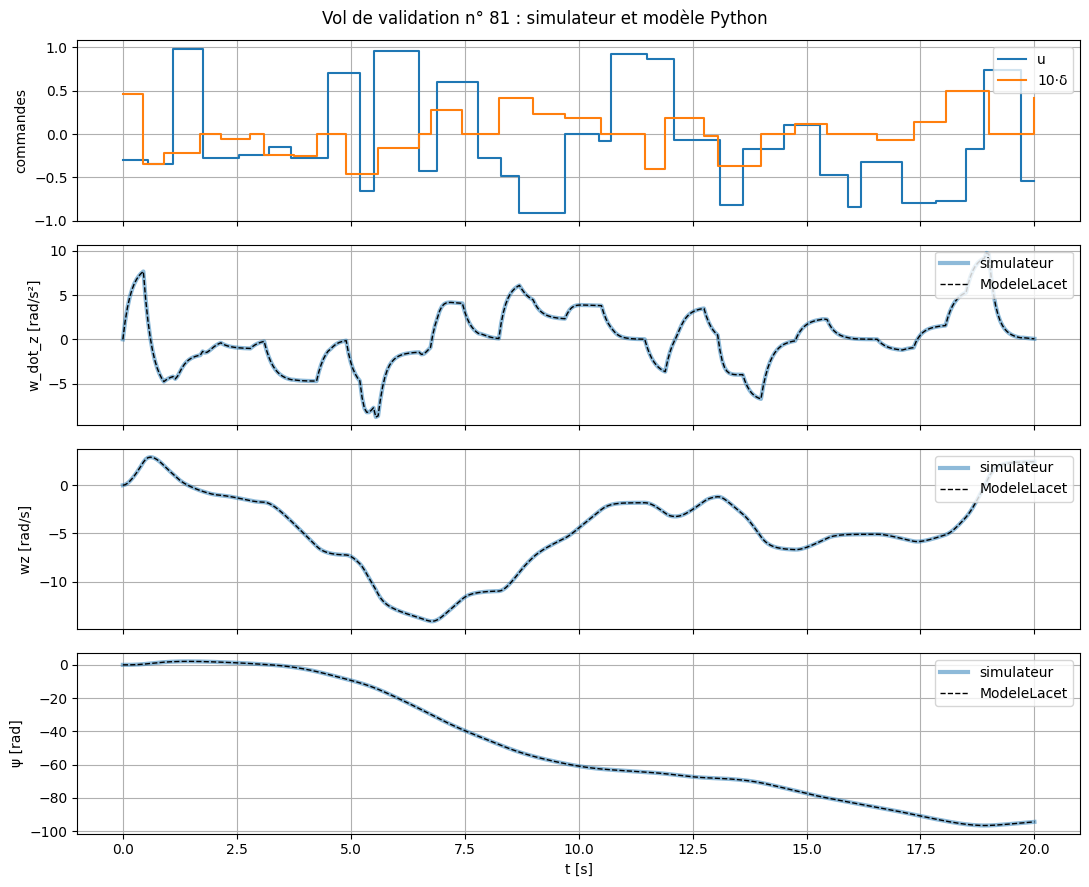

In [10]:
def rejouer(v):
    lacet = ModeleLacet()
    sortie = np.zeros((3, u.shape[1]))
    for k in range(u.shape[1] - 1):
        sortie[0, k + 1] = lacet.step(u[v, k], delta[v, k])
        sortie[1:, k + 1] = lacet.wz, lacet.psi
    return sortie

erreurs = np.array([[np.abs(rejouer(v)[1] - wz[v]).max(), np.abs(rejouer(v)[2] - psi[v]).max()] for v in range(80, 100)])
print(f"20 vols de validation, 20 s en boucle ouverte : erreur max sur wz = {erreurs[:, 0].max():.3f} rad/s, "
      f"sur ψ = {erreurs[:, 1].max():.3f} rad")

v = 80
sortie = rejouer(v)
tv = D["t"]
fig, axs = plt.subplots(4, 1, figsize=(11, 9), sharex=True)
axs[0].step(tv, u[v], where="post", label="u"); axs[0].step(tv, delta[v] * 10, where="post", label="10·δ")
axs[0].set_ylabel("commandes"); axs[0].legend(loc="upper right")
for ax, nom, y, i in [(axs[1], "w_dot_z [rad/s²]", wdz[v], 0), (axs[2], "wz [rad/s]", wz[v], 1), (axs[3], "ψ [rad]", psi[v], 2)]:
    ax.plot(tv, y, lw=3, alpha=0.5, label="simulateur")
    ax.plot(tv, sortie[i], "k--", lw=1, label="ModeleLacet")
    ax.set_ylabel(nom); ax.legend(loc="upper right")
for ax in axs:
    ax.grid(True)
axs[-1].set_xlabel("t [s]")
fig.suptitle(f"Vol de validation n° {v + 1} : simulateur et modèle Python")
plt.tight_layout()
plt.show()

## 8. Le nouvel environnement : `rl_interface/Env_drone_lacet.py`

`DroneLacetEnv` reprend `Env_drone.py` (même structure, mêmes commentaires) et ajoute le lacet. L'ancien
environnement ne change pas.

| | `Env_drone.py` | `Env_drone_lacet.py` |
|---|---|---|
| Action | $u$ | $[u, a]$, avec $\delta$ = `DELTA_MAX`$\cdot a$ et `DELTA_MAX` = 0.05 (partie 5 : le lacet est très sensible) |
| Modèles | RNN $u \to a_z$ | RNN inchangé (partie 6 : couplage négligé), plus `ModeleLacet` |
| `mission()` | $z_{ref}$ | $z_{ref}$, plus $\psi_{ref}$ et $w_{z,ref}$ : un tour entre 4 s et 6.5 s, pendant le palier à 0.5 m |
| Observation | $[e_z, v_z, a_{z,prev}/10, u_{prev}]$ | les 4 mêmes, plus $[e_\psi, (w_{z,ref} - w_z)/5, a_{prev}]$, avec $e_\psi$ ramené dans $[-\pi, \pi]$ |
| Récompense | 5 termes | les 5 mêmes, plus $-0.5\lvert e_\psi\rvert + 0.2\,e^{-(e_\psi/0.05)^2} - 0.3\,(a - a_{prev})^2$ |
| Crash | $\lvert e_z\rvert > 1$ m ou $z < -0.35$ m | en plus : $\lvert e_\psi\rvert > 1$ rad |

Ces choix découlent des simulations :
- **Une rampe sans à-coup, pas un échelon** : un échelon de $2\pi$ serait invisible une fois ramené dans
  $[-\pi, \pi]$. La consigne $\psi_{ref} = 2\pi x - \sin(2\pi x)$, avec $x$ l'avancement du tour de 0 à 1, part et
  arrive avec une vitesse nulle.
- **Le tour se fait pendant le palier**, une fois le drone stabilisé, et finit avant la descente à 7 s : pendant
  les montées, $u$ est saturé et $\delta$ est moins efficace (partie 6).
- **$w_z$ est dans l'observation**, à travers l'écart à $w_{z,ref}$. Comme il n'y a pas d'amortissement, la policy
  doit voir la vitesse de rotation pour freiner.
- Pour la récompense, la consigne de lacet est prise **à la fin du pas**, puisqu'elle bouge pendant le tour.
- Le tour en 2.5 s demande au plus $4\pi^2/2.5^2 = 6.3$ rad/s², soit $\delta \approx 0.037$ ($a \approx 0.74$).
  `DELTA_MAX` = 0.05 laisse un peu de marge.

check_env : OK


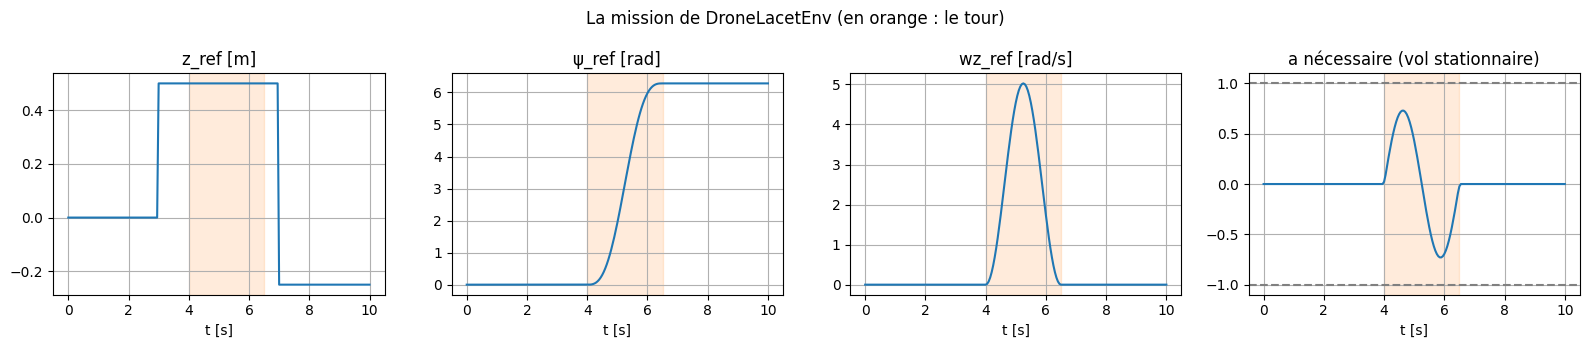

a nécessaire : au plus 0.73 (borne : 1)


In [11]:
import warnings
from Env_drone_lacet import DroneLacetEnv, DELTA_MAX, T_ROT, D_ROT
from gymnasium.utils.env_checker import check_env

env = DroneLacetEnv()
with warnings.catch_warnings():
    warnings.simplefilter("ignore")      # bornes infinies de l'observation et pas de rendu, comme Env_drone
    check_env(env)
print("check_env : OK")

tm = np.arange(0, 10 + Ts / 2, Ts)
ref = np.array([env.mission(x) for x in tm])                      # z_ref, psi_ref, wz_ref
gain = 200 * (1 - np.tanh(u_h) ** 2)
a_ff = np.gradient(ref[:, 2], Ts) / gain / DELTA_MAX              # commande a qui suivrait exactement la consigne
fig, axs = plt.subplots(1, 4, figsize=(16, 3.5))
for ax, y, titre in zip(axs, [ref[:, 0], ref[:, 1], ref[:, 2], a_ff],
                        ["z_ref [m]", "ψ_ref [rad]", "wz_ref [rad/s]", "a nécessaire (vol stationnaire)"]):
    ax.plot(tm, y); ax.set_title(titre); ax.set_xlabel("t [s]"); ax.grid(True)
    ax.axvspan(T_ROT, T_ROT + D_ROT, color="tab:orange", alpha=0.15)
axs[3].axhline(1, color="gray", ls="--"); axs[3].axhline(-1, color="gray", ls="--")
fig.suptitle("La mission de DroneLacetEnv (en orange : le tour)")
plt.tight_layout()
plt.show()
print(f"a nécessaire : au plus {np.abs(a_ff).max():.2f} (borne : 1)")

### Vols d'essai

Avant d'entraîner un agent, on vérifie que la mission est faisable et que la récompense et le crash se comportent
comme prévu. Les 4 premières valeurs de l'observation sont celles de `Env_drone`, donc **l'altitude est commandée
par la policy PPO déjà entraînée** (`rl_interface/ppo_drone.zip`). Le lacet est commandé de deux façons :
- **pas de lacet** ($a = 0$) : le drone devrait crasher pendant le tour ;
- **un PD simple** sur l'observation : $a = 1.86\,e_\psi + 0.93\,(w_{z,ref} - w_z)$, réglé pour une pulsation
  de 4 rad/s avec $\dot w_z \approx 172\,\delta$.

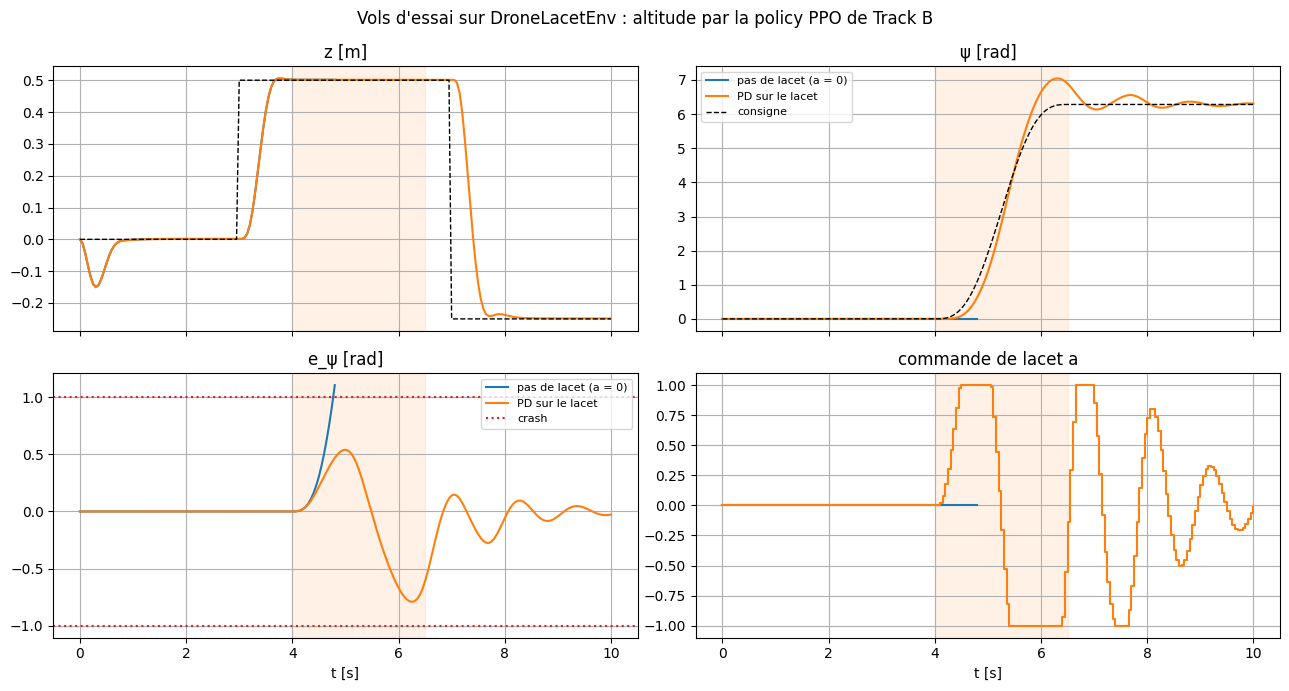

,vol,récompense,RMSE z [m],max |e_ψ| [rad],ψ final [rad],max |a|
lacet commandé par,,,,,,
pas de lacet (a = 0),crash à 4.80 s,75.318,0.135,1.106,0.000,0.0
PD sur le lacet,10 s,244.150,0.160,0.791,6.311,1.0


In [12]:
from stable_baselines3 import PPO

agent = PPO.load(str(Path("..", "rl_interface", "ppo_drone.zip")))
COMMANDES = {"pas de lacet (a = 0)": (0.0, 0.0), "PD sur le lacet": (1.86, 4.65)}   # gains sur obs[4], obs[5]

vols, lignes = {}, []
for nom, (kp, kd) in COMMANDES.items():
    obs, info = env.reset(seed=0)
    log, R = [info["m"] | {"a": 0.0}], 0.0
    while True:
        u = float(agent.predict(obs[:4], deterministic=True)[0][0])
        a = float(np.clip(kp * obs[4] + kd * obs[5], -1, 1))
        obs, r, crash, fini, info = env.step(np.array([u, a], dtype=np.float32))
        R += r
        log.append(info["m"] | {"a": a})
        if crash or fini:
            break
    L = pd.DataFrame(log)
    L["e_psi"] = np.arctan2(np.sin(L.psi_ref - L.psi), np.cos(L.psi_ref - L.psi))
    vols[nom] = L
    lignes.append([nom, f"crash à {L.t.iloc[-1]:.2f} s" if crash else "10 s", R,
                   np.sqrt(np.mean((L.z_ref - L.z) ** 2)), L.e_psi.abs().max(), L.psi.iloc[-1], L.a.abs().max()])

fig, axs = plt.subplots(2, 2, figsize=(13, 7), sharex=True)
for nom, L in vols.items():
    axs[0, 0].plot(L.t, L.z, label=nom)
    axs[0, 1].plot(L.t, L.psi, label=nom)
    axs[1, 0].plot(L.t, L.e_psi, label=nom)
    axs[1, 1].step(L.t, L.a, where="post", label=nom)
L = vols["PD sur le lacet"]
axs[0, 0].plot(L.t, L.z_ref, "k--", lw=1, label="consigne")
axs[0, 1].plot(L.t, L.psi_ref, "k--", lw=1, label="consigne")
axs[1, 0].axhline(1, color="tab:red", ls=":", label="crash")
axs[1, 0].axhline(-1, color="tab:red", ls=":")
for ax, titre in zip(axs.ravel(), ["z [m]", "ψ [rad]", "e_ψ [rad]", "commande de lacet a"]):
    ax.set_title(titre); ax.grid(True); ax.axvspan(T_ROT, T_ROT + D_ROT, color="tab:orange", alpha=0.1)
axs[0, 1].legend(fontsize=8); axs[1, 0].legend(fontsize=8)
for ax in axs[1]:
    ax.set_xlabel("t [s]")
fig.suptitle("Vols d'essai sur DroneLacetEnv : altitude par la policy PPO de Track B")
plt.tight_layout()
plt.show()

pd.DataFrame(lignes, columns=["lacet commandé par", "vol", "récompense", "RMSE z [m]", "max |e_ψ| [rad]",
                              "ψ final [rad]", "max |a|"]).set_index("lacet commandé par").round(3)

- **Sans commande de lacet, le drone crashe** quand l'erreur de lacet dépasse 1 rad, pendant le tour : la mission
  oblige bien à tourner.
- **Avec le PD, le vol va jusqu'au bout** et le tour est fait ($\psi$ final $\approx 2\pi$), mais mal. Sans
  anticipation, le PD est d'abord en retard, puis freine trop tard, en butée ($a = \pm 1$). Il dépasse la consigne
  de 0.8 rad, ce qui est proche du seuil de crash, puis oscille jusqu'à la fin du vol, car il n'y a pas
  d'amortissement naturel. C'est ce que l'agent RL devra faire mieux, en anticipant l'accélération et le freinage.
- La policy d'altitude de Track B fonctionne sans changement (RMSE ≈ 0.16 m, comme dans Track B) : le lacet ne
  perturbe pas l'altitude.

### Reste à faire
| Étape | Détail |
|---|---|
| Entraînement | PPO sur `DroneLacetEnv`, avec les réglages de `track_b.ipynb` (16 vols en parallèle) |
| Export | `export_policy.py` (à ne pas modifier) ne gère qu'une action et les mesures `t, z, vz, az_prev, z_ref, u_prev` : il faut une variante pour 2 actions et les mesures $\psi$, $w_z$, $\psi_{ref}$, $w_{z,ref}$, $a_{prev}$ |
| `rl_controller.m` | Entrées `psi`, `wz`, `a_prev`, sortie $\delta$ ; mêmes `mission()` et `observation()` qu'en Python |
| `EINT_RL_closed_loop.slx` | Mélangeur `u1 = u3 = u + δ`, `u2 = u4 = u − δ` à la place du branchement direct ; ZOH et retards sur `psi` (sortie 9) et `wz` (sortie 12) |

## Bilan

| Question | Réponse (simulations sur `UAV_model.slx`) |
|---|---|
| Paire de moteurs | **1 et 3 à $+\delta$, 2 et 4 à $-\delta$** ; les deux autres paires font basculer le drone |
| Disposition | Configuration « + » : 1 sur $+x$, 2 sur $+y$, 3 sur $-x$, 4 sur $-y$ |
| Sens de rotation | $\delta > 0$ donne $w_z > 0$ : sens direct, anti-horaire vu de dessus |
| Couplage roulis / tangage | Aucun : $w_x = w_y = 0$ |
| Couplage altitude | $\Delta a_z \approx -K\tanh u\,(1-\tanh^2 u)\,\delta^2$, soit −0.02 m/s² à $\delta = 0.05$ : négligeable |
| Modèle du lacet | $\dot w_z = 50 \sum_i s_i \tanh(m_i)$, exact, **sans amortissement** ; $\approx 172\,\delta$ en vol stationnaire (`modele_lacet.py`) |
| Environnement | `Env_drone_lacet.py` : action $[u, a]$, un tour entre 4 s et 6.5 s ; mission faisable (PD + policy d'altitude de Track B) |

Remarque sur le simulateur : dans `UAV_model.slx`, la covariance du bloc de bruit de $\theta$ vaut `seed_theta`
(jusqu'à 10 000) au lieu de $10^{-4}$. Dès que g_noise > 0, $\theta$ mesuré est très bruité. Ça n'a pas d'effet ici,
car les essais des parties 3 à 6 sont faits sans bruit.